# Cross-matching EDP2 with VSX in the Galactic Plane

In this tutorial we will:
* plot the EDP2 content in Galactic coordinates, with suggestions how to use other projections;
* select sources from the EDP2 and VSX catalogs near the Galactic Plane;
* cross-match the resulting catalogs.

## Pre-requisites

1. You have to be a [Rubin data right's holder](https://rubinobservatory.org/for-scientists/data-products/data-policy).
2. You have to have an account of the Rubin Science Platform.

### Imports

In [67]:
# Dask will be used later on to run the cross-match and extract catalogs.
import dask
import os

dask.config.set({"logging.distributed": "critical"})

from dask.distributed import Client

import logging
logger = logging.getLogger("distributed")
logger.setLevel(logging.CRITICAL)

import warnings
warnings.filterwarnings("ignore", message="Port 8787 is already in use.")

# We will use LSDB to interact with the catalogs
import lsdb

# We will use these to change between coordinate systems
# and in visualization of the results
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.visualization.wcsaxes import Quadrangle
from astropy.visualization.wcsaxes.frame import EllipticalFrame
from mocpy import WCS

# These are pretty standard imports
import numpy as np
from matplotlib import pyplot as plt

## 1. Load EDP2 and VSX content

For EDP2 we will load specific columns, because they are not included in the default set up. If you'd like to use the defaulf columns for EDP2, you can do it like this:

```
dia_object_cat = lsdb.open_catalog(base_path / "dia_object_collection")
```

In [6]:
### Paths from which we will grab the HATS catalogs for EDP2 and VSX
from upath import UPath

base_path = UPath("/rubin/lsdb_data")

# EDP2 diaObject catalog + light curves, see https://docs.lsdb.io/en/latest/tutorials/pre_executed/rubin_dp2.html
# If you'd like the default columns loaded use the line below
# dia_object_cat = lsdb.open_catalog(base_path / "dia_object_collection")

dia_object_cat = lsdb.open_catalog(
    base_path / "dia_object_collection",
    columns=[
        "diaObjectId", "ra", "dec", "nDiaSources",
        "u_scienceFluxMean", "u_scienceFluxMeanErr",
        "g_scienceFluxMean", "g_scienceFluxMeanErr",
        "r_scienceFluxMean", "r_scienceFluxMeanErr",
        "i_scienceFluxMean", "i_scienceFluxMeanErr",
        "z_scienceFluxMean", "z_scienceFluxMeanErr",
        "y_scienceFluxMean", "y_scienceFluxMeanErr",
        "diaObjectForcedSource"
    ],
)

# VSX
vsx = lsdb.open_catalog("https://data.lsdb.io/hats/vsx/")

We can look up the `dia_object_cat` and `vsx` contents. You will notice that the whole catalog is not loaded, and a small operation is run to extract a few rows.

In [7]:
dia_object_cat.head(5)

Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

diaObjectId          ra        dec  nDiaSources  \
_healpix_29                                                                   
1193171727451938021  764288743128432771  347.416883 -20.813298            2   
1193171799581950902  764288743128432802  347.361978 -20.814874            1   
1193171800801067400  764288743128432757  347.363985 -20.811534            1   
1193171801808856727  764288743128432705  347.357962 -20.812062            1   
1193171803685702889  764288743128432772  347.364499 -20.810906            1   

                     u_scienceFluxMean  u_scienceFluxMeanErr  \
_healpix_29                                                    
1193171727451938021               <NA>                  <NA>   
1193171799581950902               <NA>                  <NA>   
1193171800801067400               <NA>                  <NA>   
1193171801808856727               <NA>                  <NA>   
1193171803685702889               <NA>                  <NA>   

                     g_scienceFluxMean  g_scienceFluxMeanErr  \
_healpix_29                                                    
1193171727451938021               <NA>                  <NA>   
1193171799581950902         502.792267            113.206558   
1193171800801067400               <NA>                  <NA>   
1193171801808856727               <NA>                  <NA>   
1193171803685702889               <NA>                  <NA>   

                     r_scienceFluxMean  r_scienceFluxMeanErr  \
_healpix_29                                                    
1193171727451938021               <NA>                  <NA>   
1193171799581950902               <NA>                  <NA>   
1193171800801067400               <NA>                  <NA>   
1193171801808856727               <NA>                  <NA>   
1193171803685702889               <NA>                  <NA>   

                     i_scienceFluxMean  i_scienceFluxMeanErr  \
_healpix_29                                                    
1193171727451938021            18441.0            190.503967   
1193171799581950902               <NA>                  <NA>   
1193171800801067400        4698.418945            227.893448   
1193171801808856727        1601.044556            465.727478   
1193171803685702889        6092.471191            228.740967   

                     z_scienceFluxMean  z_scienceFluxMeanErr  \
_healpix_29                                                    
1193171727451938021               <NA>                  <NA>   
1193171799581950902               <NA>                  <NA>   
1193171800801067400               <NA>                  <NA>   
1193171801808856727               <NA>                  <NA>   
1193171803685702889               <NA>                  <NA>   

                     y_scienceFluxMean  y_scienceFluxMeanErr  \
_healpix_29                                                    
1193171727451938021               <NA>                  <NA>   
1193171799581950902               <NA>                  <NA>   
1193171800801067400               <NA>                  <NA>   
1193171801808856727               <NA>                  <NA>   
1193171803685702889               <NA>                  <NA>   

                                                 diaObjectForcedSource  
_healpix_29                                                             
1193171727451938021  [{parentObjectId: 0, coord_ra: 347.416883, coo...  
1193171799581950902  [{parentObjectId: 0, coord_ra: 347.361978, coo...  
1193171800801067400  [{parentObjectId: 0, coord_ra: 347.363985, coo...  
1193171801808856727  [{parentObjectId: 0, coord_ra: 347.357962, coo...  
1193171803685702889  [{parentObjectId: 0, coord_ra: 347.364499, coo...

In [8]:
vsx.head(5)

Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

,OID,Name,VarFlag,RAdeg,DEdeg,Type,LimitFlagOnMax,MagMax,MaxUncertaintyFlag,MaxPassband,MinIsAmplitude,LimitFlagOnMin,MagMin,MinUncertaintyFlag,MinPassband,Epoch,EpochUncertaintyFlag,LimitFlagOnPeriod,Period,PeriodUncertaintyFlag,SpectralType
_healpix_29,,,,,,,,,,,,,,,,,,,,,
7130977911402,2858311,Gaia DR3 14263587225600,0,45.13471,0.32146,ROT,<NA>,14.45,<NA>,G,<NA>,<NA>,14.48,<NA>,G,<NA>,<NA>,<NA>,<NA>,<NA>,K
7771466608754,2233803,ASASSN-V J030049.10+001937.7,0,45.20446,0.32716,ROT,<NA>,13.16,<NA>,g,Y,<NA>,0.23,<NA>,g,2459511.863,<NA>,<NA>,10.531,<NA>,<NA>
13581125322115,2857869,Gaia DR3 27148489078656,0,45.04971,0.37054,ROT,<NA>,15.08,<NA>,G,<NA>,<NA>,15.11,<NA>,G,<NA>,<NA>,<NA>,<NA>,<NA>,K
15176177971580,272629,ASAS J030023+0028.7,0,45.09492,0.47681,VAR,<NA>,9.925,<NA>,Ic,Y,<NA>,0.073,<NA>,Ic,<NA>,<NA>,<NA>,<NA>,<NA>,B6Vk
18919835635988,278769,[SIG2010] 3127463,0,45.45712,0.42707,HADS,<NA>,20.01,<NA>,r,Y,<NA>,0.28,<NA>,r,<NA>,<NA>,<NA>,0.067038,<NA>,<NA>


## 2. Plot EDP2 sky coverage in the Galactic coordinates.

We can plot EDP2 contents across the sky easily using the `plot_pixels` method. It will be however displayed in equatorial corrdinates, which is the coordinate system used across the survey.

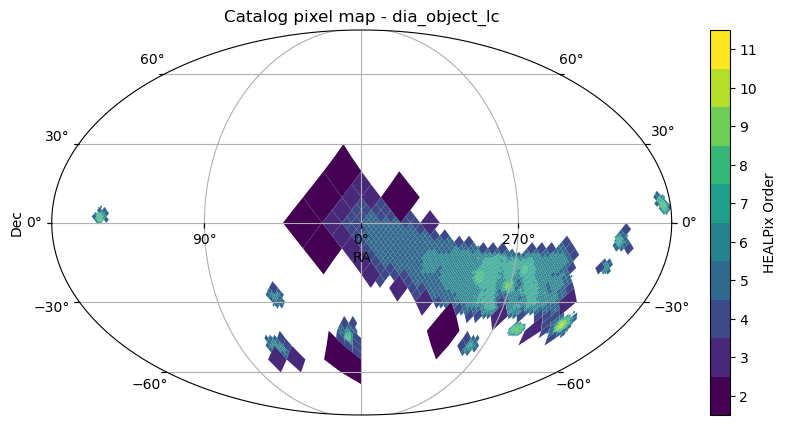

In [42]:
fig, ax = dia_object_cat.plot_pixels()
plt.show()

To plot the same data in another coordinate system, in this case Galactic, we have to define the WCS and it's center in desired projection.

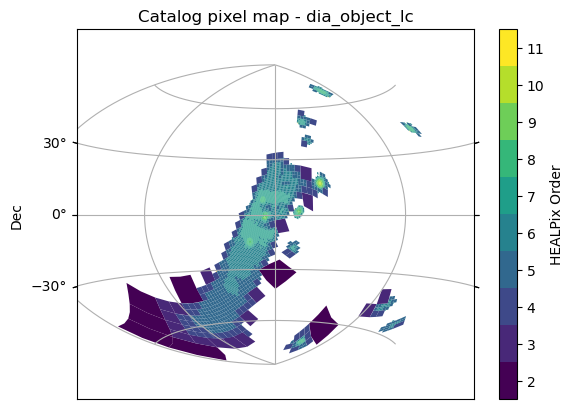

In [43]:
# To do that we have to define WCS first
fig = plt.figure()# (figsize=(20, 10))
wcs = WCS(fig, fov=200*u.deg, center=SkyCoord(l=0*u.deg, b=0*u.deg, frame='galactic'), coordsys='galactic')

# Now we can plot the catalog
_, ax = dia_object_cat.plot_pixels(wcs=wcs.w, fig=fig)
plt.show()

## Selecting EDP2 data based on a location

In order to estimate the area where we want to do our spacial query, we will first mark it on the sky plot.

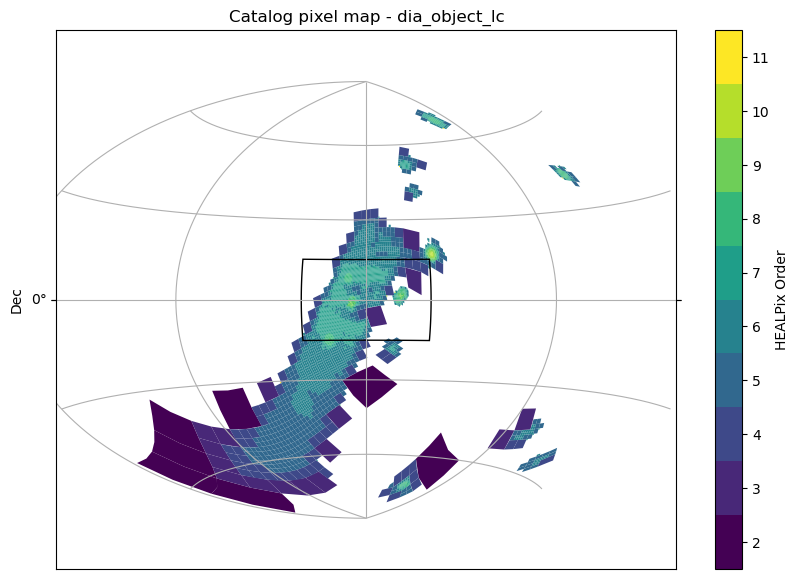

In [52]:
# To do that we have to define WCS first
fig = plt.figure(figsize=(10, 7))
wcs = WCS(fig, fov=200*u.deg, center=SkyCoord(l=0*u.deg, b=0*u.deg, frame='galactic'), coordsys='galactic')

# Now we can plot the catalog
_, ax = dia_object_cat.plot_pixels(wcs=wcs.w, fig=fig)

r1 = Quadrangle((-30.0, -15.0)*u.deg, 60*u.deg, 30*u.deg,
               edgecolor='black', facecolor='none',
               transform=ax.get_transform('galactic'))
ax.add_patch(r1)

plt.show()

Now we can define a polygon in Galactic coordinates, which we will then transform into equatorial coordinates and run a spacial query.

In [53]:
polygon_corners = np.array([[-30, -15],
                  [-30, 15],
                  [30, 15],
                  [30, -15]])

# for gal_l in l:
#     for gal_b in b:
c = SkyCoord(polygon_corners[:,0]*u.deg, polygon_corners[:,1]*u.deg, frame="galactic")
polygon_corners_eq = []
for point in c:
    polygon_corners_eq.append([point.icrs.ra.deg, point.icrs.dec.deg])

polygon_corners_eq = np.asarray(polygon_corners_eq)

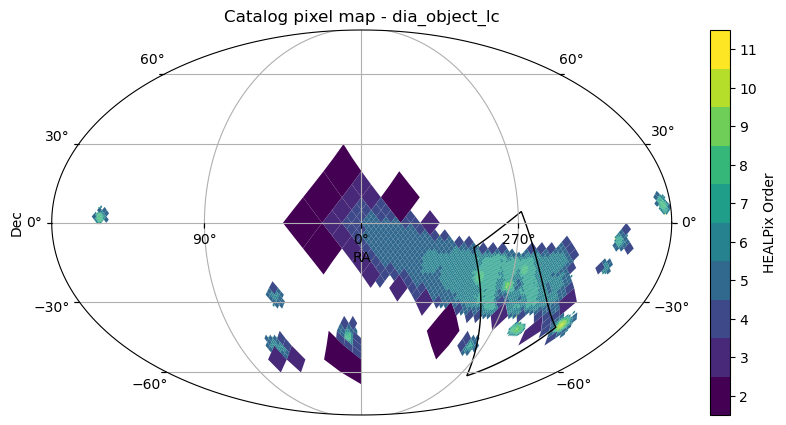

In [58]:
# This is how our selection polygon looks like in equatorial coordinates
fig, ax = dia_object_cat.plot_pixels()

r1 = Quadrangle((-30.0, -15.0)*u.deg, 60*u.deg, 30*u.deg,
               edgecolor='black', facecolor='none',
               transform=ax.get_transform('galactic'))
ax.add_patch(r1)

plt.show()

Now we can run a query on both EDP2 and VSX catalogs using the [`polygon_search` method](https://docs.lsdb.io/en/stable/reference/api/lsdb.catalog.Catalog.polygon_search.html).

In [59]:
edp2_gal = dia_object_cat.polygon_search(polygon_corners_eq)
vsx_gal = vsx.polygon_search(polygon_corners_eq)

If we display our data, we see that selected region is slightly larger than we wanted to. This is because this function selects HEALpixels that fall within the polygon we have specified.

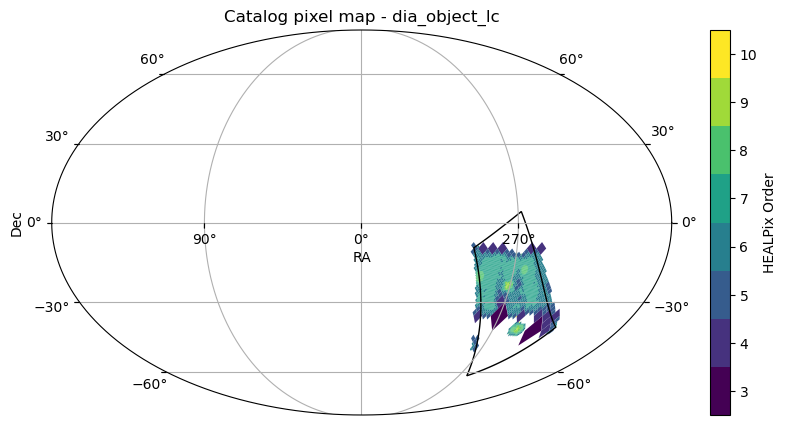

In [60]:
# This is how our selection polygon looks like in equatorial coordinates
fig, ax = edp2_gal.plot_pixels()

r1 = Quadrangle((-30.0, -15.0)*u.deg, 60*u.deg, 30*u.deg,
               edgecolor='black', facecolor='none',
               transform=ax.get_transform('galactic'))
ax.add_patch(r1)

plt.show()

This is even more striking for VSX, where because there aren't that many objects in the catalog, the HEALpix size is large.

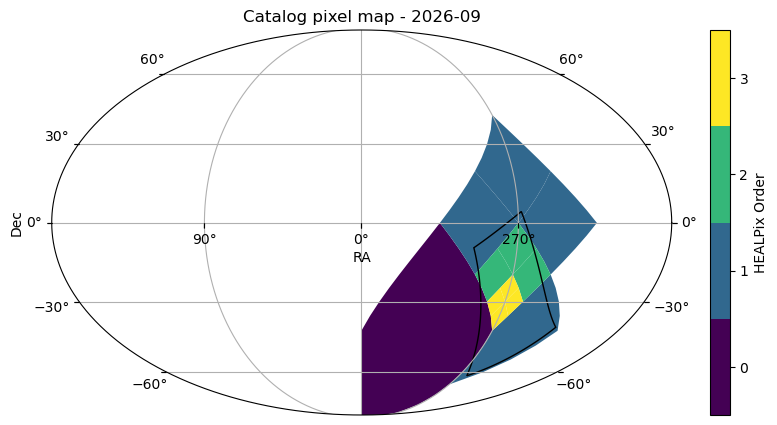

In [62]:
# This is how our selection polygon looks like in equatorial coordinates
fig, ax = vsx_gal.plot_pixels()

r1 = Quadrangle((-30.0, -15.0)*u.deg, 60*u.deg, 30*u.deg,
               edgecolor='black', facecolor='none',
               transform=ax.get_transform('galactic'))
ax.add_patch(r1)

plt.show()

## Cross-matching EDP2 and VSX selection in the Galactic plane

Before we attempt the cross-match, we will do a down-selecion of sources, to limit ourselves to those with mutliple visits.

In [63]:
edp2_gal_many = edp2_gal.query("nDiaSources > 30")

We can now cross-match our catalogs. 

In [65]:
dp2_vsx_gal = vsx_gal.crossmatch(
    edp2_gal_many,
    radius_arcsec=0.1,
    suffixes=["_vsx", "_rubin"],
    suffix_method="overlapping_columns",
)
dp2_vsx_gal

,OID,Name,VarFlag,RAdeg,DEdeg,Type,LimitFlagOnMax,MagMax,MaxUncertaintyFlag,MaxPassband,MinIsAmplitude,LimitFlagOnMin,MagMin,MinUncertaintyFlag,MinPassband,Epoch,EpochUncertaintyFlag,LimitFlagOnPeriod,Period,PeriodUncertaintyFlag,SpectralType,diaObjectId,ra,dec,nDiaSources,u_scienceFluxMean,u_scienceFluxMeanErr,g_scienceFluxMean,g_scienceFluxMeanErr,r_scienceFluxMean,r_scienceFluxMeanErr,i_scienceFluxMean,i_scienceFluxMeanErr,z_scienceFluxMean,z_scienceFluxMeanErr,y_scienceFluxMean,y_scienceFluxMeanErr,diaObjectForcedSource,_dist_arcsec
npartitions=4125,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"Order: 3, Pixel: 448",int64[pyarrow],large_string[pyarrow],int64[pyarrow],double[pyarrow],double[pyarrow],large_string[pyarrow],large_string[pyarrow],double[pyarrow],large_string[pyarrow],large_string[pyarrow],large_string[pyarrow],large_string[pyarrow],double[pyarrow],large_string[pyarrow],large_string[pyarrow],double[pyarrow],large_string[pyarrow],large_string[pyarrow],double[pyarrow],large_string[pyarrow],large_string[pyarrow],int64[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],float[pyarrow],"nested<parentObjectId: [int64], coord_ra: [dou...",double[pyarrow]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 8, Pixel: 769983",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 8, Pixel: 770026",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


As you can see, this is not a proper catalog. We have to run the pipeline to extract the crossmatched catalog. This will take around an hour.

In [ ]:
with Client(
    n_workers=4,
    threads_per_worker=1,
    memory_limit="auto",
    local_directory=f"/deleted-sundays/{os.environ.get('USER', 'dask_scratch')}",
) as client:
    display(client)
    edp2_vsx_gal_many = dp2_vsx_gal.compute()
edp2_vsx_gal_many.shape

/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/contextlib.py:148: UserWarning: Creating scratch directories is taking a surprisingly long time. (1.12s) This is often due to running workers on a network file system. Consider specifying a local-directory to point workers to write scratch data to a local disk.
  next(self.gen)


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://kkruszynska.nb.data.lsst.cloud/nb/user/kkruszynska/proxy/8787/status,
Dashboard: https://kkruszynska.nb.data.lsst.cloud/nb/user/kkruszynska/proxy/8787/status,Workers: 4
Total threads: 4,Total memory: 32.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:42943,Workers: 0
Dashboard: https://kkruszynska.nb.data.lsst.cloud/nb/user/kkruszynska/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:42315,Total threads: 1
Dashboard: https://kkruszynska.nb.data.lsst.cloud/nb/user/kkruszynska/proxy/33333/status,Memory: 8.00 GiB
Nanny: tcp://127.0.0.1:43759,


/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 9.57 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Computing Catalog:   0%|          | 0/4125 [00:00<?, ?it/s]

2026-10-02 21:12:23,380 - distributed.worker.memory - WARNING - Worker is at 80% memory usage. Pausing worker.  Process memory: 6.47 GiB -- Worker memory limit: 8.00 GiB
2026-10-02 21:12:23,488 - distributed.worker.memory - WARNING - Worker is at 79% memory usage. Resuming worker. Process memory: 6.34 GiB -- Worker memory limit: 8.00 GiB
2026-10-02 21:23:05,534 - distributed.worker.memory - WARNING - gc.collect() took 1.177s. This is usually a sign that some tasks handle too many Python objects at the same time. Rechunking the work into smaller tasks might help.
2026-10-02 21:23:05,534 - distributed.worker.memory - WARNING - Worker is at 80% memory usage. Pausing worker.  Process memory: 6.41 GiB -- Worker memory limit: 8.00 GiB
2026-10-02 21:23:06,777 - distributed.worker.memory - WARNING - Worker is at 79% memory usage. Resuming worker. Process memory: 6.37 GiB -- Worker memory limit: 8.00 GiB
2026-10-02 21:25:23,076 - distributed.worker.memory - WARNING - Worker is at 80% memory usa

You can save the result of this operation into a parquet file for later use. 

In [ ]:
edp2_vsx_gal_many.to_parquet("edp2_vsx_ga_many.parquet")